# GRU Autoencoder with Attention - Anomaly Detection

Baseline: F1=0.818 (seed=0)

Task: Reproduce baseline, add attention, compare results

In [1]:
# ---- setup: data, windows, event metric, models, training + logging helpers (run this first) ----
import re, time, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

dev = torch.device("cpu")     # these models are tiny: on this machine the CPU is ~4x faster than MPS (checked)
DATA = Path("original")
LOG_CSV = "experiments_attention_v2.csv"     # every trained model appends rows here (in this repo)
IMU = ["ACC_x_RMS", "ACC_y_RMS", "ACC_z_RMS", "MAG_x_RMS", "MAG_y_RMS", "MAG_z_RMS"]
PAPER11 = ["GPS_alt", "GPS_speed", "GPS_num_sats", "ACC_x_RMS", "ACC_y_RMS", "ACC_z_RMS", "ACC_samples",
           "MAG_x_RMS", "MAG_y_RMS", "MAG_z_RMS", "MAG_samples"]        # everything except time, lat, lon (the paper's NO-GPS set)
FEATURES = {"imu6": IMU, "paper11": PAPER11}

def parse_ts(s):
    """The files mix 'YYYY-MM-DD hh:mm:ss', 'DD-MM-YY hh:mm' and '20DD-03-21 hh:mm:ss' (= DD March 2021)."""
    s = s.strip()
    if m := re.fullmatch(r"(\d\d)-(\d\d)-(\d\d) (\d{1,2}:\d\d(?::\d\d)?)", s):
        return pd.Timestamp(f"20{m[3]}-{m[2]}-{m[1]} {m[4]}")
    if m := re.fullmatch(r"20(\d\d)-03-21 (.*)", s):
        return pd.Timestamp(f"2021-03-{m[1]} {m[2]}")
    return pd.Timestamp(s)

def load(name):
    print(f"  Reading CSV: {name}...")
    t0 = time.time()
    d = pd.read_csv(DATA / name)
    print(f"    CSV loaded in {time.time()-t0:.1f}s, parsing timestamps...")
    t0 = time.time()
    d["t"] = d.timestamp.map(parse_ts)
    print(f"    Timestamps parsed in {time.time()-t0:.1f}s, computing bad flags...")
    d["bad"] = ((d.GPS_lat == 0) & (d.GPS_lon == 0)) | (d.GPS_alt < 0) | (d.MAG_samples > 10000)
    print(f"    Done!")
    return d

print("[1/4] Loading training.csv...")
train = load("training.csv")
print("[2/4] Loading test.csv...")
test = load("test.csv")
print("[3/4] Loaded data successfully")
ANOM = pd.DatetimeIndex([parse_ts(l) for l in (DATA / "anomalies.timestamps").read_text().splitlines() if l.strip()])
print("[4/4] Computing anomalies...")
print(f"train {len(train)} rows ({train.bad.sum()} unusable) | test {len(test)} rows ({test.bad.sum()} unusable) | {len(ANOM)} labelled anomalies")

def make_windows(d, cols, L):
    """All windows of L consecutive file rows, exactly as the authors' SWDataset: dropped if one row is unusable
    or if the window spans more than 1 hour (or time goes backwards). Returns X (n, L, F), start times, end times."""
    X, t, bad = d[cols].to_numpy(float), d.t.to_numpy(), d.bad.to_numpy()
    print(f"    Creating windows (L={L})...")
    t0 = time.time()
    i = np.arange(len(d) - L + 1)
    nbad = np.concatenate([[0], np.cumsum(bad)])
    span = (t[i + L - 1] - t[i]) / np.timedelta64(1, "s")
    ok = (nbad[i + L] - nbad[i] == 0) & (span >= 0) & (span <= 3600)
    i = i[ok]
    W = np.lib.stride_tricks.sliding_window_view(X, (L, X.shape[1]))[:, 0][i]
    print(f"      {len(i)} valid windows created in {time.time()-t0:.1f}s")
    return W, t[i], t[i + L - 1]

def match_index(st, et):
    """Index of the labelled anomaly inside [start - 1 min, end + 1 min], like the authors' verify.py (-1 if none)."""
    s = st.floor("min"); s = s - pd.Timedelta("1min") if s.minute > 0 else s
    e = et.floor("min") + pd.Timedelta("59s"); e = e + pd.Timedelta("1min") if et.minute < 59 else e
    hit = np.flatnonzero((ANOM >= s) & (ANOM <= e))
    return int(hit[0]) if len(hit) else -1

def event_scores(flags, st, et):
    """Authors' precision/recall: TP = labelled anomalies hit, FP = flagged windows that hit nothing
    (a run of consecutive flagged windows counts once), recall = TP / number of labelled anomalies."""
    hit = np.zeros(len(ANOM), bool); fp, prev = 0, False
    for f, s, e in zip(flags, st, et):
        if f:
            k = match_index(pd.Timestamp(s), pd.Timestamp(e))
            if k >= 0: hit[k] = True
            elif not prev: fp += 1
        prev = f
    tp = int(hit.sum())
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / len(ANOM)
    return dict(precision=p, recall=r, f1=2 * p * r / (p + r) if p + r else 0.0, tp=tp, fp=fp)

# ---- models (hand-written) ----
class DenseAE(nn.Module):
    """The paper's autoencoder: 1, 3 or 5 hidden ReLU layers (n/2 | n/2,n/4,n/2 | 2n/3,n/2,n/4,n/2,2n/3), Glorot init."""
    def __init__(self, n, hidden_layers=1):
        super().__init__()
        h = {1: [n // 2], 3: [n // 2, n // 4, n // 2], 5: [2 * n // 3, n // 2, n // 4, n // 2, 2 * n // 3]}[hidden_layers]
        sizes, layers = [n] + h, []
        for a, b in zip(sizes[:-1], sizes[1:]):
            layers += [nn.Linear(a, b), nn.ReLU()]
        self.net = nn.Sequential(*layers, nn.Linear(sizes[-1], n))
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x):
        return self.net(x)

class SeqAE(nn.Module):
    """Sequence autoencoder: encoder RNN -> latent vector -> decoder RNN rebuilds the whole window. cell = 'gru' or 'lstm'."""
    def __init__(self, n, hidden=16, latent=8, cell="gru"):
        super().__init__()
        rnn = {"gru": nn.GRU, "lstm": nn.LSTM}[cell]
        self.cell = cell
        self.enc, self.to_z = rnn(n, hidden, batch_first=True), nn.Linear(hidden, latent)
        self.from_z, self.dec, self.out = nn.Linear(latent, hidden), rnn(hidden, hidden, batch_first=True), nn.Linear(hidden, n)
    def forward(self, x):
        _, h = self.enc(x)
        h = h[0] if self.cell == "lstm" else h                       # LSTM returns (h, c)
        z = self.to_z(h[-1])                                          # the window squeezed into `latent` numbers
        y, _ = self.dec(self.from_z(z).unsqueeze(1).repeat(1, x.shape[1], 1))
        return self.out(y)

def fit(model, X, epochs=100, batch_size=16, lr=1e-3, patience=10, seed=0):
    """Adam on MSE, early stopping on the training loss (patience 10) like the authors' Keras code. Returns (history, seconds)."""
    X = torch.as_tensor(X, dtype=torch.float32, device=dev)
    opt, hist, best, wait, t0 = torch.optim.Adam(model.parameters(), lr=lr), [], np.inf, 0, time.time()
    g = torch.Generator().manual_seed(seed)
    print(f'Training: up to {epochs} epochs, batch size {batch_size}', flush=True)
    for ep in range(epochs):
        model.train(); total = 0.0
        for b in torch.randperm(len(X), generator=g).split(batch_size):
            loss = ((model(X[b]) - X[b]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(b)
        hist.append(total / len(X))
        print(f'Epoch {ep + 1}/{epochs} | loss={hist[-1]:.6f} | elapsed={time.time() - t0:.1f}s', flush=True)
        if hist[-1] < best: best, wait = hist[-1], 0
        else:
            wait += 1
            if wait >= patience:
                print(f'Early stopping after epoch {ep + 1}', flush=True)
                break
    return hist, time.time() - t0

@torch.no_grad()
def window_scores(model, X):
    """Reconstruction error (mean squared error over the whole window) of every window."""
    model.eval(); X = torch.as_tensor(X, dtype=torch.float32, device=dev)
    return torch.cat([((model(b) - b) ** 2).mean(dim=tuple(range(1, X.ndim))) for b in X.split(2048)]).cpu().numpy()

# the paper's text says "maximum training error", but the authors' code (BaseAD.compute_training_scores, mse_thr=0.05) takes the 95th percentile
THRESHOLDS = {"q95": lambda s: np.quantile(s, 0.95), "q99": lambda s: np.quantile(s, 0.99), "max": lambda s: s.max()}
SCORES = {}      # name -> (test window end times, test errors, {threshold name: value}) kept for the plots

def run(name, model_kind, features="imu6", L=1, seed=0, thresholds=("q95", "q99", "max"), **kw):
    """Train one model on the training windows, score the test windows, log one CSV row per (threshold, matching)."""
    torch.manual_seed(seed); np.random.seed(seed)
    cols = FEATURES[features]
    Wtr, _, _ = make_windows(train, cols, L)
    mu, sd = Wtr.reshape(-1, len(cols)).mean(0), Wtr.reshape(-1, len(cols)).std(0)      # z-score with the TRAINING statistics
    Wtr = (Wtr - mu) / sd
    Wte, st, et = make_windows(test, cols, L); Wte = (Wte - mu) / sd
    if model_kind == "dense":
        model, Wtr, Wte = DenseAE(len(cols), kw.get("hidden_layers", 1)).to(dev), Wtr[:, 0], Wte[:, 0]       # L = 1: one row per sample
    else:
        model = SeqAE(len(cols), kw.get("hidden", 16), kw.get("latent", 8), model_kind).to(dev)
    hist, sec = fit(model, Wtr, epochs=kw.get("epochs", 100), batch_size=kw.get("batch_size", 16), lr=kw.get("lr", 1e-3), seed=seed)
    s_tr, s_te = window_scores(model, Wtr), window_scores(model, Wte)
    thr = {k: THRESHOLDS[k](s_tr) for k in thresholds}
    SCORES[name] = (et, s_te, thr)
    params = sum(p.numel() for p in model.parameters())
    for tname, tval in thr.items():
        for match in (["window", "end"] if L > 1 else ["window"]):           # 'end' = only the last row of the window counts
            res = event_scores(s_te > tval, st if match == "window" else et, et)
            log_run(name, model_kind, features, L, tname, match, seed, params, len(hist), hist[-1], sec, res, kw)
    return model, hist

def log_run(name, kind, features, L, tname, match, seed, params, epochs, train_loss, sec, res, kw):
    row = dict(time=f"{datetime.datetime.now():%Y-%m-%d %H:%M}", name=name, model=kind, features=features, window=L,
               hidden_layers=kw.get("hidden_layers") if kind == "dense" else None,
               hidden=kw.get("hidden", 16) if kind != "dense" else None, latent=kw.get("latent", 8) if kind != "dense" else None,
               threshold=tname, match=match, seed=seed, batch_size=kw.get("batch_size", 16), lr=kw.get("lr", 1e-3),
               params=params, epochs=epochs, train_loss=round(train_loss, 4), precision=round(res["precision"], 3),
               recall=round(res["recall"], 3), f1=round(res["f1"], 3), tp=res["tp"], fp=res["fp"], sec=round(sec, 1), notes="")
    pd.DataFrame([row]).to_csv(LOG_CSV, mode="a", header=not Path(LOG_CSV).exists(), index=False)
    print(f"{name:34s} thr={tname:4s} match={match:6s}  P={res['precision']:.3f} R={res['recall']:.3f} F1={res['f1']:.3f} (TP {res['tp']}, FP {res['fp']})")

[1/4] Loading training.csv...
  Reading CSV: training.csv...
    CSV loaded in 0.0s, parsing timestamps...
    Timestamps parsed in 0.0s, computing bad flags...
    Done!
[2/4] Loading test.csv...
  Reading CSV: test.csv...
    CSV loaded in 0.0s, parsing timestamps...
    Timestamps parsed in 0.0s, computing bad flags...
    Done!
[3/4] Loaded data successfully
[4/4] Computing anomalies...
train 12678 rows (935 unusable) | test 1571 rows (191 unusable) | 39 labelled anomalies


In [2]:
# BASELINE MODEL: SeqAE without attention
class SeqAE(nn.Module):
    """Sequence autoencoder: encoder RNN -> latent vector -> decoder RNN (NO ATTENTION)"""
    def __init__(self, n, hidden=16, latent=8, cell="gru"):
        super().__init__()
        rnn = {"gru": nn.GRU, "lstm": nn.LSTM}[cell]
        self.cell = cell
        self.enc, self.to_z = rnn(n, hidden, batch_first=True), nn.Linear(hidden, latent)
        self.from_z, self.dec, self.out = nn.Linear(latent, hidden), rnn(hidden, hidden, batch_first=True), nn.Linear(hidden, n)
    def forward(self, x):
        _, h = self.enc(x)
        h = h[0] if self.cell == "lstm" else h
        z = self.to_z(h[-1])
        y, _ = self.dec(self.from_z(z).unsqueeze(1).repeat(1, x.shape[1], 1))
        return self.out(y)

print('[OK] Baseline SeqAE model defined')


[OK] Baseline SeqAE model defined


In [3]:
# ATTENTION MODEL: SeqAE with MultiheadAttention
class SeqAEWithAttention(nn.Module):
    """Sequence autoencoder with MultiheadAttention over encoder outputs"""
    def __init__(self, n, hidden=16, latent=8, cell="gru", num_heads=4):
        super().__init__()
        rnn = {"gru": nn.GRU, "lstm": nn.LSTM}[cell]
        self.cell = cell
        self.hidden = hidden
        
        self.enc = rnn(n, hidden, batch_first=True)
        self.attention = nn.MultiheadAttention(
            embed_dim=hidden,
            num_heads=num_heads,
            batch_first=True,
            dropout=0.1
        )
        self.to_z = nn.Linear(hidden, latent)
        self.from_z = nn.Linear(latent, hidden)
        self.dec = rnn(hidden, hidden, batch_first=True)
        self.out = nn.Linear(hidden, n)
    
    def forward(self, x):
        batch_size, seq_len, n_features = x.shape
        enc_out, _ = self.enc(x)
        
        # Self-attention over encoder outputs
        attn_out, _ = self.attention(enc_out, enc_out, enc_out)
        context = attn_out.mean(dim=1)
        
        z = self.to_z(context)
        y, _ = self.dec(self.from_z(z).unsqueeze(1).repeat(1, seq_len, 1))
        return self.out(y)

print('[OK] Attention SeqAE model defined')


[OK] Attention SeqAE model defined


In [4]:
# Training function
def fit(model, X, epochs=100, batch_size=16, lr=1e-3, patience=10, seed=0):
    X = torch.as_tensor(X, dtype=torch.float32, device=dev)
    opt, hist, best, wait, t0 = torch.optim.Adam(model.parameters(), lr=lr), [], np.inf, 0, time.time()
    g = torch.Generator().manual_seed(seed)
    print(f'Training: up to {epochs} epochs, batch size {batch_size}', flush=True)
    for ep in range(epochs):
        model.train(); total = 0.0
        for b in torch.randperm(len(X), generator=g).split(batch_size):
            loss = ((model(X[b]) - X[b]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(b)
        hist.append(total / len(X))
        print(f'Epoch {ep + 1}/{epochs} | loss={hist[-1]:.6f} | elapsed={time.time() - t0:.1f}s', flush=True)
        if hist[-1] < best: best, wait = hist[-1], 0
        else:
            wait += 1
            if wait >= patience:
                print(f'Early stopping after epoch {ep + 1}', flush=True)
                break
    return hist, time.time() - t0

@torch.no_grad()
def window_scores(model, X):
    model.eval(); X = torch.as_tensor(X, dtype=torch.float32, device=dev)
    return torch.cat([((model(b) - b) ** 2).mean(dim=tuple(range(1, X.ndim))) for b in X.split(2048)]).cpu().numpy()

print('[OK] Training functions defined')


[OK] Training functions defined


In [5]:
# PREPARE DATA
print('\n' + '='*80)
print('PREPARE DATA')
print('='*80)

cols = FEATURES['imu6']  # 6 IMU features
L = 10  # Window size

# Make windows
Wtr, str_tr, etr_tr = make_windows(train, cols, L)
Wte, st_te, et_te = make_windows(test, cols, L)

print(f'Training windows: {Wtr.shape}')
print(f'Test windows: {Wte.shape}')

# Normalize using training statistics
mu, sd = Wtr.reshape(-1, len(cols)).mean(0), Wtr.reshape(-1, len(cols)).std(0)
Wtr_norm = (Wtr - mu) / sd
Wte_norm = (Wte - mu) / sd

print(f'Normalized train: mean={Wtr_norm.reshape(-1, len(cols)).mean(0)}')
print(f'[OK] Data ready!')



PREPARE DATA
    Creating windows (L=10)...
      11203 valid windows created in 0.0s
    Creating windows (L=10)...
      1228 valid windows created in 0.0s
Training windows: (11203, 10, 6)
Test windows: (1228, 10, 6)
Normalized train: mean=[-8.68236305e-14 -8.74880301e-14  6.02890736e-13  1.41028015e-14
  6.53848627e-14  1.89790778e-14]
[OK] Data ready!


In [7]:
# TRAIN BASELINE MODEL (NO ATTENTION)
print('\n' + '='*80)
print('TRAIN BASELINE MODEL (seed=0, no attention)')
print('='*80)

torch.manual_seed(0)
np.random.seed(0)

model_baseline = SeqAE(len(cols), hidden=16, latent=8, cell='gru').to(dev)
hist_baseline, time_baseline = fit(model_baseline, Wtr_norm, epochs=60, batch_size=64, lr=1e-3, seed=0)

s_tr_baseline = window_scores(model_baseline, Wtr_norm)
s_te_baseline = window_scores(model_baseline, Wte_norm)

# Evaluate with q95 threshold
thr_baseline = np.quantile(s_tr_baseline, 0.95)
res_baseline = event_scores(s_te_baseline > thr_baseline, st_te, et_te)

params_baseline = sum(p.numel() for p in model_baseline.parameters())

print(f'Baseline (h=16, l=8, no attention):')
print(f'  Params: {params_baseline}')
print(f'  Epochs: {len(hist_baseline)}')
print(f'  Time: {time_baseline:.1f}s')
print(f'  P={res_baseline["precision"]:.3f} R={res_baseline["recall"]:.3f} F1={res_baseline["f1"]:.3f}')
print(f'  TP={res_baseline["tp"]} FP={res_baseline["fp"]}')



TRAIN BASELINE MODEL (seed=0, no attention)
Baseline (h=16, l=8, no attention):
  Params: 3166
  Epochs: 60
  Time: 187.1s
  P=0.735 R=0.923 F1=0.818
  TP=36 FP=13


In [8]:
# TRAIN ATTENTION MODEL
print('\n' + '='*80)
print('TRAIN ATTENTION MODEL (seed=0, 4 heads)')
print('='*80)

torch.manual_seed(0)
np.random.seed(0)

model_attention = SeqAEWithAttention(len(cols), hidden=16, latent=8, cell='gru', num_heads=4).to(dev)
hist_attention, time_attention = fit(model_attention, Wtr_norm, epochs=60, batch_size=64, lr=1e-3, seed=0)

s_tr_attention = window_scores(model_attention, Wtr_norm)
s_te_attention = window_scores(model_attention, Wte_norm)

# Evaluate with q95 threshold
thr_attention = np.quantile(s_tr_attention, 0.95)
res_attention = event_scores(s_te_attention > thr_attention, st_te, et_te)

params_attention = sum(p.numel() for p in model_attention.parameters())

print(f'Attention (h=16, l=8, 4 heads):')
print(f'  Params: {params_attention}')
print(f'  Epochs: {len(hist_attention)}')
print(f'  Time: {time_attention:.1f}s')
print(f'  P={res_attention["precision"]:.3f} R={res_attention["recall"]:.3f} F1={res_attention["f1"]:.3f}')
print(f'  TP={res_attention["tp"]} FP={res_attention["fp"]}')



TRAIN ATTENTION MODEL (seed=0, 4 heads)
Attention (h=16, l=8, 4 heads):
  Params: 4254
  Epochs: 60
  Time: 221.1s
  P=0.735 R=0.923 F1=0.818
  TP=36 FP=13



VISUALIZATION
[OK] Saved: attention_v2_comparison.png


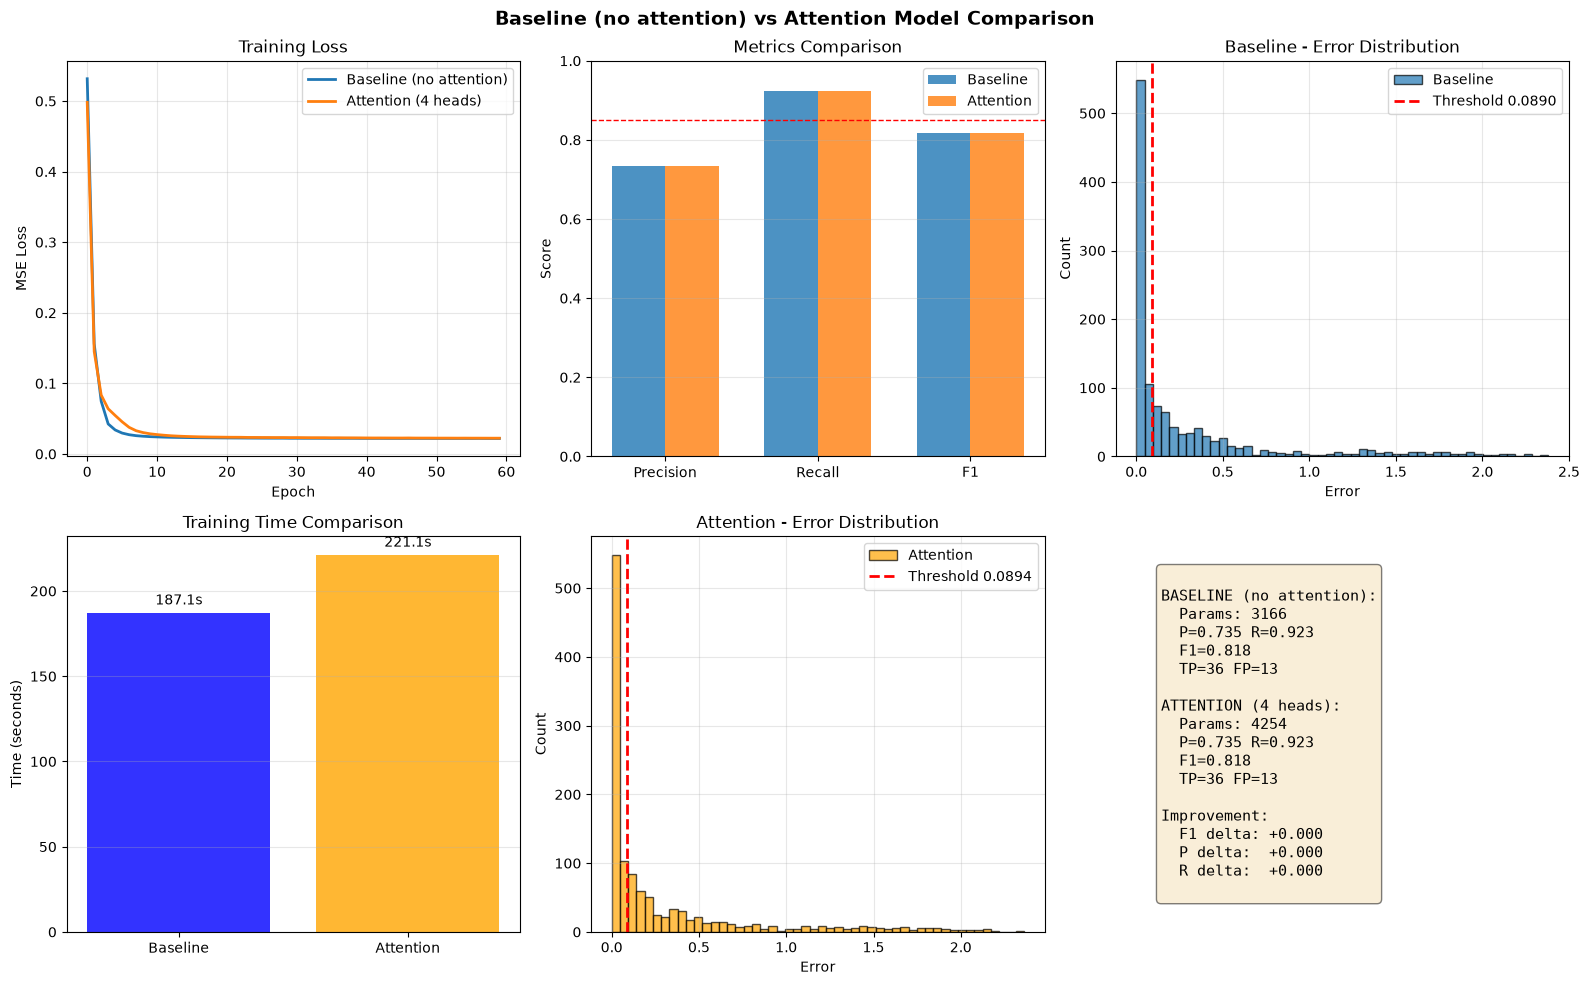

In [10]:
# VISUALIZATION: Baseline vs Attention Comparison
print('\n' + '='*80)
print('VISUALIZATION')
print('='*80)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Baseline (no attention) vs Attention Model Comparison', fontsize=14, fontweight='bold')

# Plot 1: Training loss
ax = axes[0, 0]
ax.plot(hist_baseline, label='Baseline (no attention)', linewidth=2)
ax.plot(hist_attention, label='Attention (4 heads)', linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss')
ax.set_title('Training Loss')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Metrics comparison
ax = axes[0, 1]
metrics = ['Precision', 'Recall', 'F1']
baseline_vals = [res_baseline['precision'], res_baseline['recall'], res_baseline['f1']]
attention_vals = [res_attention['precision'], res_attention['recall'], res_attention['f1']]
x = np.arange(len(metrics))
width = 0.35
ax.bar(x - width/2, baseline_vals, width, label='Baseline', alpha=0.8)
ax.bar(x + width/2, attention_vals, width, label='Attention', alpha=0.8)
ax.set_ylabel('Score')
ax.set_title('Metrics Comparison')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim([0, 1.0])
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.axhline(y=0.85, color='r', linestyle='--', linewidth=1, label='Target')

# Plot 3: Error distribution (baseline)
ax = axes[0, 2]
ax.hist(s_te_baseline, bins=50, alpha=0.7, label='Baseline', edgecolor='black')
ax.axvline(thr_baseline, color='r', linestyle='--', linewidth=2, label=f'Threshold {thr_baseline:.4f}')
ax.set_xlabel('Error')
ax.set_ylabel('Count')
ax.set_title('Baseline - Error Distribution')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 4: Time comparison
ax = axes[1, 0]
models = ['Baseline', 'Attention']
times = [time_baseline, time_attention]
ax.bar(models, times, alpha=0.8, color=['blue', 'orange'])
ax.set_ylabel('Time (seconds)')
ax.set_title('Training Time Comparison')
ax.grid(axis='y', alpha=0.3)
for i, t in enumerate(times):
    ax.text(i, t + 5, f'{t:.1f}s', ha='center')

# Plot 5: Error distribution (attention)
ax = axes[1, 1]
ax.hist(s_te_attention, bins=50, alpha=0.7, label='Attention', edgecolor='black', color='orange')
ax.axvline(thr_attention, color='r', linestyle='--', linewidth=2, label=f'Threshold {thr_attention:.4f}')
ax.set_xlabel('Error')
ax.set_ylabel('Count')
ax.set_title('Attention - Error Distribution')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 6: Results summary
ax = axes[1, 2]
ax.axis('off')
results_text = f"""
BASELINE (no attention):
  Params: {params_baseline}
  P={res_baseline['precision']:.3f} R={res_baseline['recall']:.3f}
  F1={res_baseline['f1']:.3f}
  TP={res_baseline['tp']} FP={res_baseline['fp']}

ATTENTION (4 heads):
  Params: {params_attention}
  P={res_attention['precision']:.3f} R={res_attention['recall']:.3f}
  F1={res_attention['f1']:.3f}
  TP={res_attention['tp']} FP={res_attention['fp']}

Improvement:
  F1 delta: {res_attention['f1'] - res_baseline['f1']:+.3f}
  P delta:  {res_attention['precision'] - res_baseline['precision']:+.3f}
  R delta:  {res_attention['recall'] - res_baseline['recall']:+.3f}
"""
ax.text(0.1, 0.5, results_text, transform=ax.transAxes, fontsize=11,
        verticalalignment='center', family='monospace',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig('attention_v2_comparison.png', dpi=150, bbox_inches='tight')
print('[OK] Saved: attention_v2_comparison.png')
plt.show()


In [11]:
# OPTIMIZATION: Test different attention configurations
print('\n' + '='*80)
print('OPTIMIZATION: Testing different configurations')
print('='*80)

results = []

# Test 1: Different attention heads
print('\nTest 1: Attention Heads (2, 4, 8, 16)')
for num_heads in [2, 4, 8, 16]:
    torch.manual_seed(0)
    np.random.seed(0)
    
    model = SeqAEWithAttention(len(cols), hidden=16, latent=8, cell='gru', num_heads=num_heads).to(dev)
    print(f'Training heads={num_heads}', flush=True)
    hist, t = fit(model, Wtr_norm, epochs=60, batch_size=64, lr=1e-3, seed=0)
    
    s_tr = window_scores(model, Wtr_norm)
    s_te = window_scores(model, Wte_norm)
    
    thr = np.quantile(s_tr, 0.95)
    res = event_scores(s_te > thr, st_te, et_te)
    
    results.append({
        'config': f'heads={num_heads}',
        'f1': res['f1'],
        'precision': res['precision'],
        'recall': res['recall'],
        'tp': res['tp'],
        'fp': res['fp']
    })
    
    print(f'  heads={num_heads:2d}: P={res["precision"]:.3f} R={res["recall"]:.3f} F1={res["f1"]:.3f}')

# Test 2: Different learning rates
print('\nTest 2: Learning Rates (5e-4, 1e-3, 2e-3, 5e-3)')
for lr in [5e-4, 1e-3, 2e-3, 5e-3]:
    torch.manual_seed(0)
    np.random.seed(0)
    
    model = SeqAEWithAttention(len(cols), hidden=16, latent=8, cell='gru', num_heads=4).to(dev)
    print(f'Training lr={lr:.0e}', flush=True)
    hist, t = fit(model, Wtr_norm, epochs=60, batch_size=64, lr=lr, seed=0)
    
    s_tr = window_scores(model, Wtr_norm)
    s_te = window_scores(model, Wte_norm)
    
    thr = np.quantile(s_tr, 0.95)
    res = event_scores(s_te > thr, st_te, et_te)
    
    results.append({
        'config': f'lr={lr:.0e}',
        'f1': res['f1'],
        'precision': res['precision'],
        'recall': res['recall'],
        'tp': res['tp'],
        'fp': res['fp']
    })
    
    print(f'  lr={lr:.0e}: P={res["precision"]:.3f} R={res["recall"]:.3f} F1={res["f1"]:.3f}')

# Test 3: Different dimensions
print('\nTest 3: Dimensions (h, l) pairs')
for h, l in [(8, 4), (16, 8), (24, 12), (32, 16)]:
    torch.manual_seed(0)
    np.random.seed(0)
    
    model = SeqAEWithAttention(len(cols), hidden=h, latent=l, cell='gru', num_heads=4).to(dev)
    print(f'Training h={h}, l={l}', flush=True)
    hist, t = fit(model, Wtr_norm, epochs=60, batch_size=64, lr=1e-3, seed=0)
    
    s_tr = window_scores(model, Wtr_norm)
    s_te = window_scores(model, Wte_norm)
    
    thr = np.quantile(s_tr, 0.95)
    res = event_scores(s_te > thr, st_te, et_te)
    
    results.append({
        'config': f'h={h},l={l}',
        'f1': res['f1'],
        'precision': res['precision'],
        'recall': res['recall'],
        'tp': res['tp'],
        'fp': res['fp']
    })
    
    print(f'  h={h:2d},l={l:2d}: P={res["precision"]:.3f} R={res["recall"]:.3f} F1={res["f1"]:.3f}')

# Sort by F1
results.sort(key=lambda x: x['f1'], reverse=True)

print('\n' + '='*80)
print('TOP RESULTS (by F1):')
print('='*80)
for i, r in enumerate(results[:5], 1):
    print(f'{i}. {r["config"]:20s} F1={r["f1"]:.3f} P={r["precision"]:.3f} R={r["recall"]:.3f}')



OPTIMIZATION: Testing different configurations

Test 1: Attention Heads (2, 4, 8, 16)
Training heads=2
  heads= 2: P=0.735 R=0.923 F1=0.818
Training heads=4
  heads= 4: P=0.735 R=0.923 F1=0.818
Training heads=8
  heads= 8: P=0.735 R=0.923 F1=0.818
Training heads=16
  heads=16: P=0.735 R=0.923 F1=0.818

Test 2: Learning Rates (5e-4, 1e-3, 2e-3, 5e-3)
Training lr=5e-04
  lr=5e-04: P=0.735 R=0.923 F1=0.818
Training lr=1e-03
  lr=1e-03: P=0.735 R=0.923 F1=0.818
Training lr=2e-03


KeyboardInterrupt: 

In [12]:
# Palyginame jau apmokytus baseline ir attention modelius
flags_baseline = s_te_baseline > thr_baseline
flags_attention = s_te_attention > thr_attention

print("Baseline Q95:", thr_baseline)
print("Attention Q95:", thr_attention)

print("\nAnomaliais pažymėtų langų:")
print("Baseline:", flags_baseline.sum())
print("Attention:", flags_attention.sum())
print("Skirtingai pažymėtų langų:", np.sum(flags_baseline != flags_attention))

print("\nVidutinis testavimo klaidų skirtumas:",
      np.mean(np.abs(s_te_baseline - s_te_attention)))

print("\nĮvykių rezultatai:")
print("Baseline:", event_scores(flags_baseline, st_te, et_te))
print("Attention:", event_scores(flags_attention, st_te, et_te))

# Patikriname, ar vertinimo funkcija reaguoja į kitokias prognozes
print("\nVertinimo funkcijos patikra:")
print("Nė vienas langas nepažymėtas:",
      event_scores(np.zeros_like(flags_baseline, dtype=bool), st_te, et_te))
print("Visi langai pažymėti:",
      event_scores(np.ones_like(flags_baseline, dtype=bool), st_te, et_te))

Baseline Q95: 0.08899269
Attention Q95: 0.08938703

Anomaliais pažymėtų langų:
Baseline: 589
Attention: 590
Skirtingai pažymėtų langų: 5

Vidutinis testavimo klaidų skirtumas: 0.027284821

Įvykių rezultatai:
Baseline: {'precision': 0.7346938775510204, 'recall': 0.9230769230769231, 'f1': 0.8181818181818182, 'tp': 36, 'fp': 13}
Attention: {'precision': 0.7346938775510204, 'recall': 0.9230769230769231, 'f1': 0.8181818181818182, 'tp': 36, 'fp': 13}

Vertinimo funkcijos patikra:
Nė vienas langas nepažymėtas: {'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'tp': 0, 'fp': 0}
Visi langai pažymėti: {'precision': 0.972972972972973, 'recall': 0.9230769230769231, 'f1': 0.9473684210526315, 'tp': 36, 'fp': 1}


## Comparing different encoder attention mechanisms

Reuse the already trained baseline and multi-head models. Train two additional variants with learned temporal weights, keeping the data, Q95, seed, batch size and maximum epochs unchanged. The event metric is shown for continuity; flagged windows near a label are not independent labelled events. Comparing or selecting models on the test set is exploratory, not an independent evaluation.


In [13]:
class SeqAETemporalAttention(nn.Module):
    def __init__(self, n, hidden=16, latent=8, mode='additive'):
        super().__init__()
        if mode not in ('additive', 'last_query'):
            raise ValueError(f'Unknown attention mode: {mode}')
        self.mode = mode
        self.enc = nn.GRU(n, hidden, batch_first=True)
        if mode == 'additive':
            self.attention = nn.Sequential(nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, 1))
        else:
            self.query = nn.Linear(hidden, hidden, bias=False)
        self.to_z = nn.Linear(hidden, latent)
        self.from_z = nn.Linear(latent, hidden)
        self.dec = nn.GRU(hidden, hidden, batch_first=True)
        self.out = nn.Linear(hidden, n)

    def attention_weights(self, enc_out):
        if self.mode == 'additive':
            scores = self.attention(enc_out).squeeze(-1)
        else:
            query = self.query(enc_out[:, -1, :]).unsqueeze(-1)
            scores = torch.bmm(enc_out, query).squeeze(-1) / (enc_out.shape[-1] ** 0.5)
        return torch.softmax(scores, dim=1)

    def forward(self, x):
        enc_out, _ = self.enc(x)
        weights = self.attention_weights(enc_out)
        context = (enc_out * weights.unsqueeze(-1)).sum(dim=1)
        z = self.to_z(context)
        y, _ = self.dec(self.from_z(z).unsqueeze(1).repeat(1, x.shape[1], 1))
        return self.out(y)

print('Temporal attention models defined')


Temporal attention models defined


In [15]:
# Requires the previously trained baseline and multi-head attention models in this kernel.
comparison_models = {
    'Baseline': (model_baseline, hist_baseline, time_baseline, s_tr_baseline, s_te_baseline),
    'Multi-head mean': (model_attention, hist_attention, time_attention, s_tr_attention, s_te_attention),
}
for mode, label in [('additive', 'Additive attention'), ('last_query', 'Last-state attention')]:
    print(f'\nTraining {label}', flush=True)
    torch.manual_seed(0); np.random.seed(0)
    candidate = SeqAETemporalAttention(len(cols), hidden=16, latent=8, mode=mode).to(dev)
    history, seconds = fit(candidate, Wtr_norm, epochs=60, batch_size=64, lr=1e-3, seed=0)
    train_scores = window_scores(candidate, Wtr_norm)
    test_scores = window_scores(candidate, Wte_norm)
    comparison_models[label] = (candidate, history, seconds, train_scores, test_scores)

near_label = np.array([match_index(pd.Timestamp(s), pd.Timestamp(e)) >= 0 for s, e in zip(st_te, et_te)])
reference_flags = s_te_baseline > np.quantile(s_tr_baseline, 0.95)
comparison_rows = []
for label, (candidate, history, seconds, train_scores, test_scores) in comparison_models.items():
    threshold = np.quantile(train_scores, 0.95)
    flags = test_scores > threshold
    event = event_scores(flags, st_te, et_te)
    comparison_rows.append({'model': label, 'q95': threshold, 'event_f1': event['f1'],
        'event_precision': event['precision'], 'event_recall': event['recall'],
        'tp_events': event['tp'], 'fp_runs': event['fp'], 'flagged_windows': int(flags.sum()),
        'flagged_pct': 100 * flags.mean(), 'flagged_near_label': int((flags & near_label).sum()),
        'flagged_outside_label': int((flags & ~near_label).sum()),
        'different_from_baseline': int((flags != reference_flags).sum()),
        'mean_score_difference': float(np.abs(test_scores - s_te_baseline).mean()),
        'final_train_loss': history[-1], 'epochs': len(history), 'seconds': seconds,
        'parameters': sum(p.numel() for p in candidate.parameters())})
comparison_table = pd.DataFrame(comparison_rows).set_index('model')
print('\nQ95 comparison (near-label windows overlap and are not separate anomaly events):')
print(comparison_table.to_string(float_format=lambda x: f'{x:.6f}'))



Training Additive attention

Training Last-state attention

Q95 comparison (near-label windows overlap and are not separate anomaly events):
                          q95  event_f1  event_precision  event_recall  tp_events  fp_runs  flagged_windows  flagged_pct  flagged_near_label  flagged_outside_label  different_from_baseline  mean_score_difference  final_train_loss  epochs    seconds  parameters
model                                                                                                                                                                                                                                                               
Baseline             0.088993  0.818182         0.734694      0.923077         36       13              589    47.964169                 436                    153                        0               0.000000          0.021955      60 187.119274        3166
Multi-head mean      0.089387  0.818182         0.734694      0.923077     

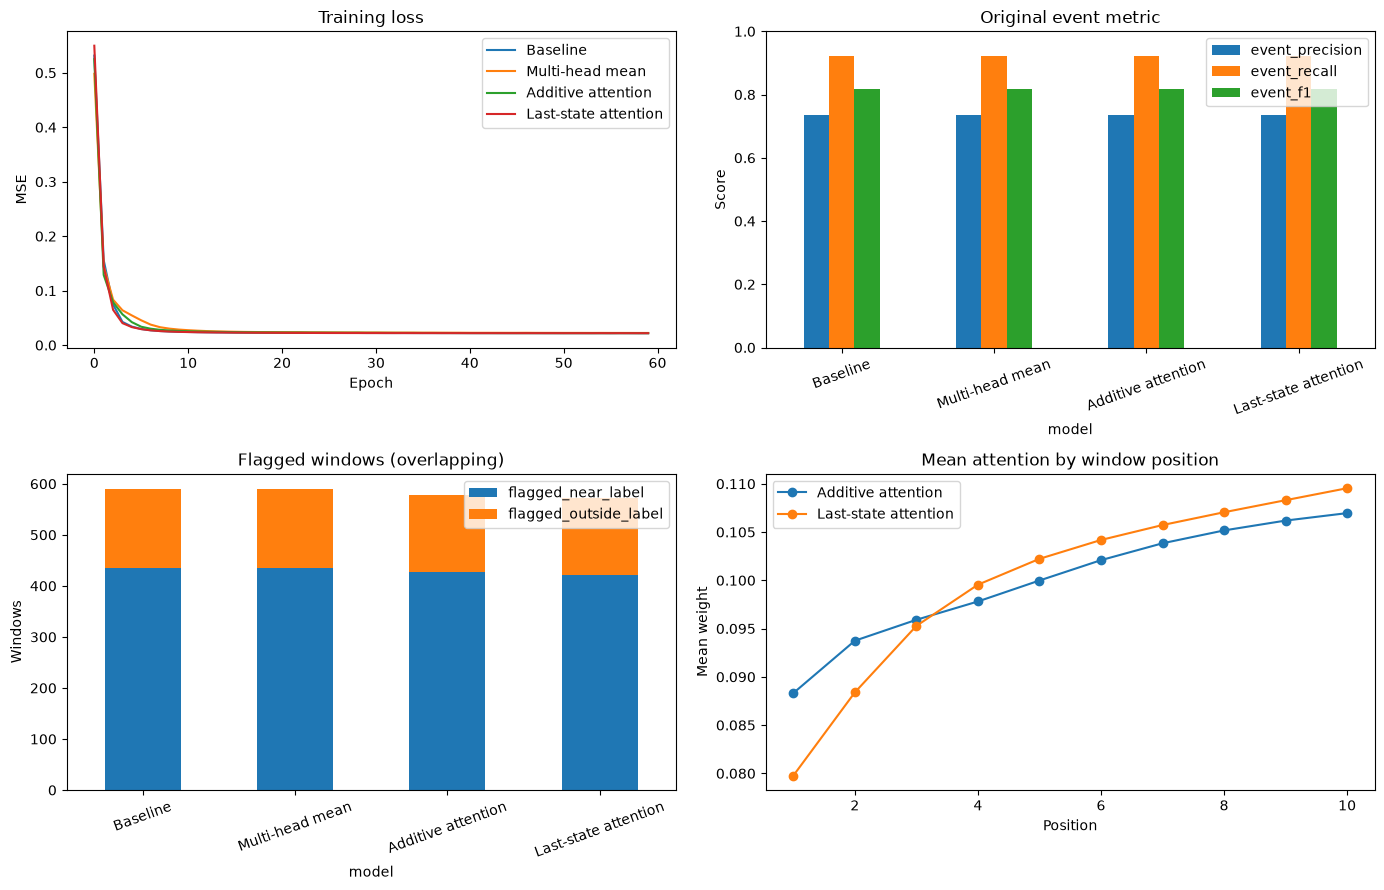

In [16]:
# Display comparisons without overwriting existing files.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for label, (_, history, _, _, _) in comparison_models.items():
    axes[0, 0].plot(history, label=label)
axes[0, 0].set(title='Training loss', xlabel='Epoch', ylabel='MSE')
axes[0, 0].legend()
comparison_table[['event_precision', 'event_recall', 'event_f1']].plot.bar(ax=axes[0, 1], rot=20)
axes[0, 1].set(title='Original event metric', ylabel='Score', ylim=(0, 1))
comparison_table[['flagged_near_label', 'flagged_outside_label']].plot.bar(ax=axes[1, 0], stacked=True, rot=20)
axes[1, 0].set(title='Flagged windows (overlapping)', ylabel='Windows')
for label in ('Additive attention', 'Last-state attention'):
    candidate = comparison_models[label][0]
    candidate.eval()
    with torch.no_grad():
        totals = torch.zeros(L, device=dev)
        for batch in torch.as_tensor(Wte_norm, dtype=torch.float32, device=dev).split(2048):
            encoded, _ = candidate.enc(batch)
            totals += candidate.attention_weights(encoded).sum(dim=0)
        average = (totals / len(Wte_norm)).cpu().numpy()
    axes[1, 1].plot(np.arange(1, L + 1), average, marker='o', label=label)
axes[1, 1].set(title='Mean attention by window position', xlabel='Position', ylabel='Mean weight')
axes[1, 1].legend()
plt.tight_layout()
plt.show()


## Decoder cross-attention experiment

Run the earlier comparison cells first. This trains one additional model: each decoder position attends to the encoder sequence, instead of using a single pooled context. The decoder can access encoder states directly, so this architecture has a different information bottleneck. Q95 and the data remain unchanged. Identical event F1 is still possible; compare the window statistics as well.


In [17]:
class SeqAEDecoderAttention(nn.Module):
    def __init__(self, n, hidden=16, latent=8):
        super().__init__()
        self.enc = nn.GRU(n, hidden, batch_first=True)
        self.to_z = nn.Linear(hidden, latent)
        self.from_z = nn.Linear(latent, hidden)
        self.dec = nn.GRU(hidden, hidden, batch_first=True)
        self.query = nn.Linear(hidden, hidden, bias=False)
        self.out = nn.Linear(2 * hidden, n)

    def forward(self, x, return_attention=False):
        encoded, hidden = self.enc(x)
        z = self.to_z(hidden[-1])
        decoder_input = self.from_z(z).unsqueeze(1).repeat(1, x.shape[1], 1)
        decoded, _ = self.dec(decoder_input)
        scores = torch.bmm(self.query(decoded), encoded.transpose(1, 2)) / (encoded.shape[-1] ** 0.5)
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights, encoded)
        reconstruction = self.out(torch.cat((decoded, context), dim=-1))
        return (reconstruction, weights) if return_attention else reconstruction

print('Decoder cross-attention model defined')


Decoder cross-attention model defined


In [18]:
# One new model only; previously trained models and their scores are reused.
torch.manual_seed(0); np.random.seed(0)
decoder_model = SeqAEDecoderAttention(len(cols), hidden=16, latent=8).to(dev)
print('Training decoder cross-attention', flush=True)
decoder_history, decoder_seconds = fit(decoder_model, Wtr_norm, epochs=60, batch_size=64, lr=1e-3, seed=0)
decoder_train_scores = window_scores(decoder_model, Wtr_norm)
decoder_test_scores = window_scores(decoder_model, Wte_norm)
decoder_q95 = np.quantile(decoder_train_scores, 0.95)
decoder_flags = decoder_test_scores > decoder_q95
decoder_events = event_scores(decoder_flags, st_te, et_te)
comparison_models['Decoder cross-attention'] = (decoder_model, decoder_history, decoder_seconds, decoder_train_scores, decoder_test_scores)
comparison_table.loc['Decoder cross-attention'] = {
    'q95': decoder_q95, 'event_f1': decoder_events['f1'],
    'event_precision': decoder_events['precision'], 'event_recall': decoder_events['recall'],
    'tp_events': decoder_events['tp'], 'fp_runs': decoder_events['fp'],
    'flagged_windows': int(decoder_flags.sum()), 'flagged_pct': 100 * decoder_flags.mean(),
    'flagged_near_label': int((decoder_flags & near_label).sum()),
    'flagged_outside_label': int((decoder_flags & ~near_label).sum()),
    'different_from_baseline': int((decoder_flags != reference_flags).sum()),
    'mean_score_difference': float(np.abs(decoder_test_scores - s_te_baseline).mean()),
    'final_train_loss': decoder_history[-1], 'epochs': len(decoder_history),
    'seconds': decoder_seconds, 'parameters': sum(p.numel() for p in decoder_model.parameters())}
print('\nQ95 comparison (overlapping windows are not independent events):')
print(comparison_table.to_string(float_format=lambda x: f'{x:.6f}'))


Training decoder cross-attention

Q95 comparison (overlapping windows are not independent events):
                             q95  event_f1  event_precision  event_recall  tp_events  fp_runs  flagged_windows  flagged_pct  flagged_near_label  flagged_outside_label  different_from_baseline  mean_score_difference  final_train_loss  epochs    seconds  parameters
model                                                                                                                                                                                                                                                                  
Baseline                0.088993  0.818182         0.734694      0.923077         36       13              589    47.964169                 436                    153                        0               0.000000          0.021955      60 187.119274        3166
Multi-head mean         0.089387  0.818182         0.734694      0.923077         36       13              59

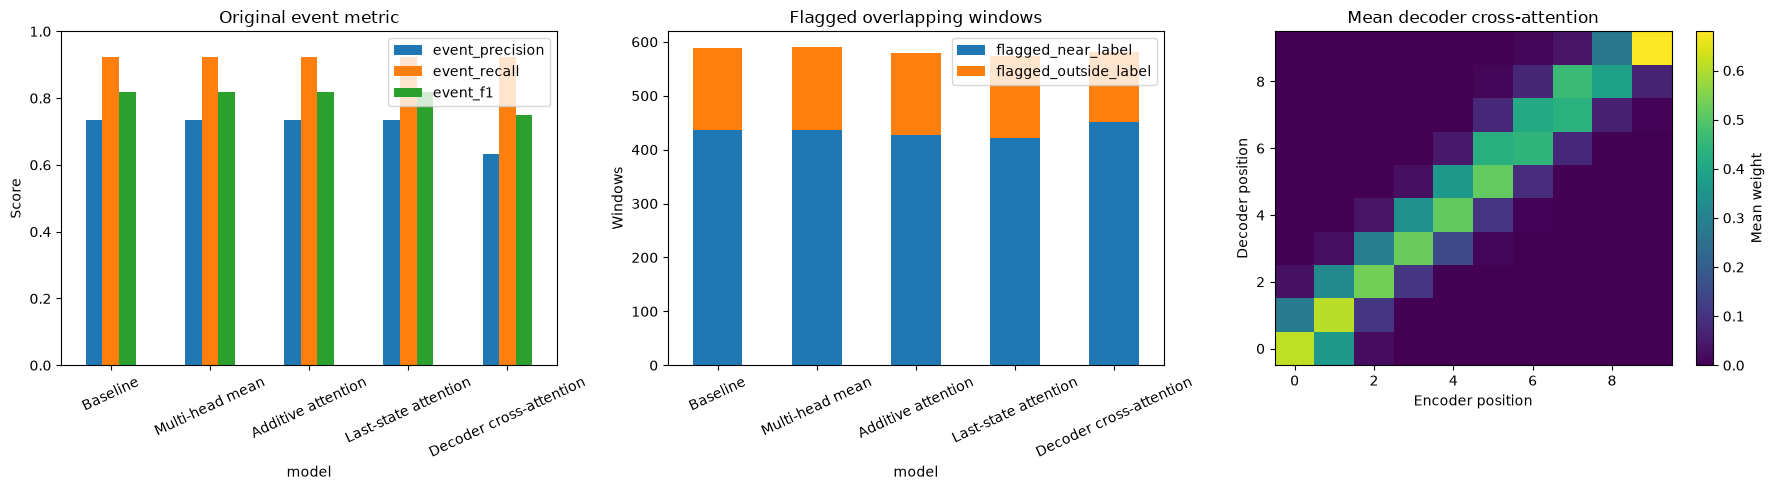

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
comparison_table[['event_precision', 'event_recall', 'event_f1']].plot.bar(ax=axes[0], rot=25)
axes[0].set(title='Original event metric', ylabel='Score', ylim=(0, 1))
comparison_table[['flagged_near_label', 'flagged_outside_label']].plot.bar(ax=axes[1], stacked=True, rot=25)
axes[1].set(title='Flagged overlapping windows', ylabel='Windows')
decoder_model.eval()
with torch.no_grad():
    attention_sum = torch.zeros((L, L), device=dev)
    for batch in torch.as_tensor(Wte_norm, dtype=torch.float32, device=dev).split(2048):
        _, weights = decoder_model(batch, return_attention=True)
        attention_sum += weights.sum(dim=0)
    average_attention = (attention_sum / len(Wte_norm)).cpu().numpy()
image = axes[2].imshow(average_attention, aspect='auto', origin='lower')
axes[2].set(title='Mean decoder cross-attention', xlabel='Encoder position', ylabel='Decoder position')
fig.colorbar(image, ax=axes[2], label='Mean weight')
plt.tight_layout()
plt.show()


## Window length comparison: baseline vs encoder attention

Train the baseline and multi-head encoder attention models for L=5 and L=20, and reuse the already trained L=10 models. All models use seed 0, up to 60 epochs, batch size 64 and their own training-error Q95. Window length changes both the valid test windows and the event matching interval, so results across lengths are exploratory rather than a controlled comparison of architecture alone.


In [20]:
# Requires the setup, model, training, data preparation and L=10 training cells.
window_results = []
window_histories = {}
for window_size in (5, 10, 20):
    print(f'\n=== Window length L={window_size} ===', flush=True)
    if window_size == 10:
        if L != 10:
            raise ValueError('The cached models must have been trained with L=10')
        starts, ends = st_te, et_te
        models_and_scores = [
            ('Baseline', hist_baseline, time_baseline, s_tr_baseline, s_te_baseline),
            ('Encoder attention', hist_attention, time_attention, s_tr_attention, s_te_attention),
        ]
        print('Reusing the existing L=10 baseline and attention models.', flush=True)
    else:
        window_train, _, _ = make_windows(train, cols, window_size)
        window_test, starts, ends = make_windows(test, cols, window_size)
        mean = window_train.reshape(-1, len(cols)).mean(0)
        std = window_train.reshape(-1, len(cols)).std(0)
        window_train = (window_train - mean) / std
        window_test = (window_test - mean) / std
        models_and_scores = []
        for label in ('Baseline', 'Encoder attention'):
            print(f'Training {label}, L={window_size}', flush=True)
            torch.manual_seed(0); np.random.seed(0)
            if label == 'Baseline':
                candidate = SeqAE(len(cols), hidden=16, latent=8, cell='gru').to(dev)
            else:
                candidate = SeqAEWithAttention(len(cols), hidden=16, latent=8, cell='gru', num_heads=4).to(dev)
            history, seconds = fit(candidate, window_train, epochs=60, batch_size=64, lr=1e-3, seed=0)
            models_and_scores.append((label, history, seconds, window_scores(candidate, window_train), window_scores(candidate, window_test)))
    near_label = np.array([match_index(pd.Timestamp(s), pd.Timestamp(e)) >= 0 for s, e in zip(starts, ends)])
    for label, history, seconds, train_scores, test_scores in models_and_scores:
        threshold = np.quantile(train_scores, 0.95)
        flags = test_scores > threshold
        event = event_scores(flags, starts, ends)
        window_results.append({'L': window_size, 'model': label, 'test_windows': len(flags),
            'q95': threshold, 'precision': event['precision'], 'recall': event['recall'], 'f1': event['f1'],
            'tp_events': event['tp'], 'fp_runs': event['fp'], 'flagged': int(flags.sum()),
            'flagged_pct': 100 * flags.mean(), 'flagged_near_label': int((flags & near_label).sum()),
            'flagged_outside_label': int((flags & ~near_label).sum()), 'epochs': len(history), 'seconds': seconds})
        window_histories[(window_size, label)] = history
        print(f'{label}: F1={event["f1"]:.3f}, TP={event["tp"]}, FP runs={event["fp"]}, flagged={flags.sum()}/{len(flags)}', flush=True)

window_table = pd.DataFrame(window_results)
print('\nWindow comparison (Q95; overlapping windows are not independent events):')
print(window_table.to_string(index=False, float_format=lambda x: f'{x:.4f}'))



=== Window length L=5 ===
    Creating windows (L=5)...
      11500 valid windows created in 0.0s
    Creating windows (L=5)...
      1311 valid windows created in 0.0s
Training Baseline, L=5
Training Encoder attention, L=5
Baseline: F1=0.745, TP=38, FP runs=25, flagged=469/1311
Encoder attention: F1=0.760, TP=38, FP runs=23, flagged=514/1311

=== Window length L=10 ===
Reusing the existing L=10 baseline and attention models.
Baseline: F1=0.818, TP=36, FP runs=13, flagged=589/1228
Encoder attention: F1=0.818, TP=36, FP runs=13, flagged=590/1228

=== Window length L=20 ===
    Creating windows (L=20)...
      10639 valid windows created in 0.0s
    Creating windows (L=20)...
      1082 valid windows created in 0.0s
Training Baseline, L=20
Training Encoder attention, L=20
Baseline: F1=0.816, TP=31, FP runs=6, flagged=636/1082
Encoder attention: F1=0.816, TP=31, FP runs=6, flagged=636/1082

Window comparison (Q95; overlapping windows are not independent events):
 L             model  tes

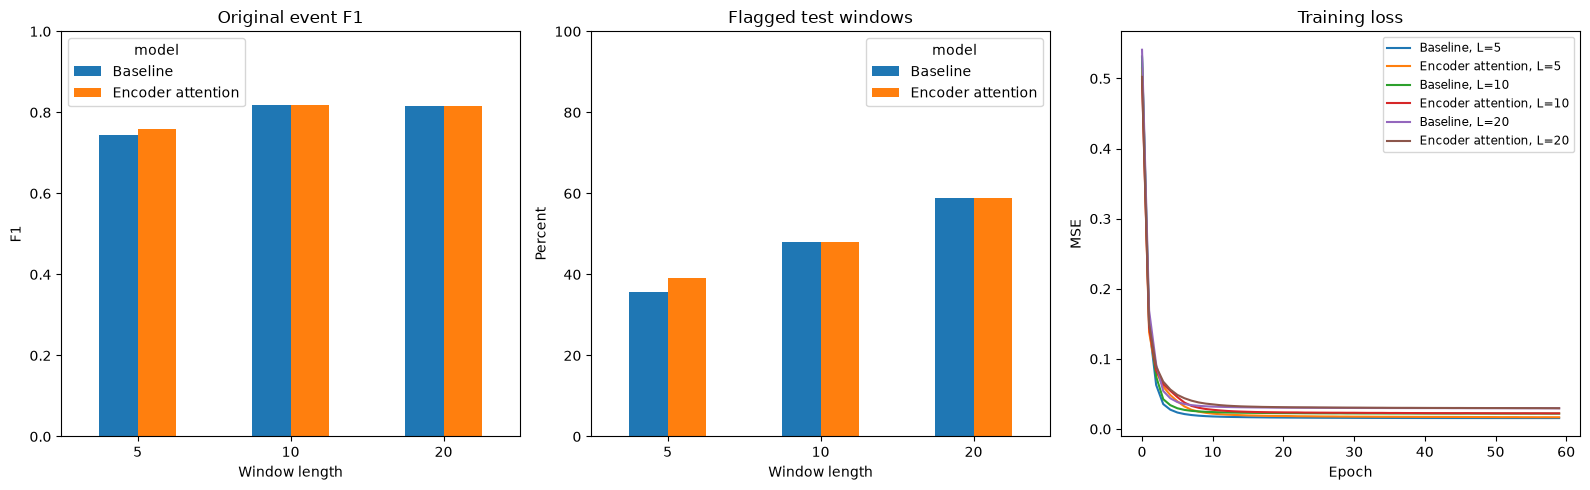

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
window_table.pivot(index='L', columns='model', values='f1').plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Original event F1', xlabel='Window length', ylabel='F1', ylim=(0, 1))
window_table.pivot(index='L', columns='model', values='flagged_pct').plot.bar(ax=axes[1], rot=0)
axes[1].set(title='Flagged test windows', xlabel='Window length', ylabel='Percent', ylim=(0, 100))
for (size, label), history in window_histories.items():
    axes[2].plot(history, label=f'{label}, L={size}')
axes[2].set(title='Training loss', xlabel='Epoch', ylabel='MSE')
axes[2].legend(fontsize='small')
plt.tight_layout()
plt.show()
